# 05 — País: la base de cruces por manzana para todas las comunas

Generaliza lo hecho en Independencia (notebooks 02–04) a las 346 comunas. Cada comuna es independiente: su conjunta comunal sale de su microdato y sus restricciones salen de sus manzanas. Por comuna se ajusta el modelo de 27 bloques, se guarda $W$ (interno, no se publica) y se exportan los **cruces bivariados por manzana**, que forman la base final.

**Decisiones**
- *Base final:* todos los cruces de a pares entre los 27 bloques (351 pares, incluida la categoría "resto" de cada bloque), por manzana, en formato largo: `MANZENT, var1, cat1, var2, cat2, conteo`. Los bordes son dato publicado y el interior es inferido. Cualquier otra tabla se arma desde $W$.
- *Comunas bajo umbral (51, 0,8% de la población):* el microdato trae `edad = -66` para todas sus personas, así que el bloque de edad no se puede armar. Quedan para un paso aparte.
- *Cómputo:* el ajuste usa `ipf_perfiles_gpu_rapido`: las mismas actualizaciones del IPF, con $W$ en float32, sumas por categoría acumuladas en doble precisión y dos kernels propios. Es ~10× más rápido que la versión del notebook 03.
- *Convergencia:* cada celda restringida debe cumplir $|\text{error}| \le \max(0{,}1;\ 0{,}01\%\cdot n_{per})$ de su manzana, y cada perfil $|\text{error}| \le \max(0{,}1;\ 0{,}01\%\cdot\mu_p)$. El tope es de 20.000 iteraciones: si no converge, el modelo se guarda igual con su error y queda marcado. El avance se anota en `resultados/pais/logs/` y $W$ se guarda cada 2.500 iteraciones en `resultados/pais/checkpoints/`, así que un ajuste cortado se retoma donde quedó. E3 explica por qué no basta la tolerancia absoluta de 0,1 personas.

**Pasos de este notebook**
- E0. Preparación: una lectura de cada CSV nacional, que deja un parquet por comuna.
- E1. Diagnóstico de todas las comunas, sin ajustar.
- E2. Regresión: Independencia con la versión rápida vs el modelo del notebook 03.
- E3. Piloto con comunas de distintos tamaños.
- E4. Extrapolación de tiempo y disco al país.

La corrida nacional (E5) se agrega cuando el piloto esté revisado. Todo es retomable: si un modelo ya existe en `resultados/pais/modelos/`, se carga en vez de reajustarse.

In [1]:
import os
import time

import numpy as np
import pandas as pd

from manzanas.pais import RUTA_COMUNAS, RUTA_LOGS, RUTA_MODELOS, RUTA_PAIS, diagnosticar_comuna, preparar_pais, procesar_comuna
from manzanas.perfiles import cargar_modelo

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
TOL = 0.1       # personas: piso del error permitido por celda
TOL_REL = 1e-4  # 0,01% de la manzana: error permitido en manzanas grandes
N_ITER = 20000  # tope de iteraciones por comuna
os.makedirs(RUTA_PAIS, exist_ok=True)
print("resultados en:", RUTA_PAIS)

resultados en: resultados/pais


### E0. Preparación: un parquet por comuna

Cada CSV nacional se lee una sola vez, con los tipos inferidos sobre el país completo, y se escribe un parquet por comuna en `resultados/pais/comunas/`. Si ya están, no se rehace.

In [2]:
# E0. Separar los CSV nacionales en un parquet por comuna (solo la primera vez)
n_existentes = len([f for f in os.listdir(RUTA_COMUNAS) if f.startswith("personas_")]) if os.path.exists(RUTA_COMUNAS) else 0
if n_existentes < 346:
    t0 = time.time()
    preparar_pais()
    print(f"listo en {(time.time() - t0) / 60:.1f} min")
archivos = os.listdir(RUTA_COMUNAS)
for tabla in ["personas", "hogares", "viviendas", "manzanas"]:
    print(f"{tabla:<10}: {sum(f.startswith(tabla + '_') for f in archivos)} comunas")
assert sum(f.startswith("personas_") for f in archivos) == 346

personas  : 346 comunas
hogares   : 346 comunas
viviendas : 346 comunas
manzanas  : 346 comunas


### E1. Diagnóstico de todas las comunas

Para cada comuna, sin ajustar nada: personas, manzanas, si el total de personas coincide con la suma de `n_per`, si está bajo umbral (`-66`) y si el inventario de 82 marginales pasa sus chequeos. Si pasa, también el número de perfiles y el tamaño de $W$ (perfiles × manzanas), que determina memoria y tiempo.

In [3]:
# E1. Diagnóstico por comuna (~ minutos): tamaño del problema y chequeos del inventario
cuts = sorted(int(f[len("personas_"):-len(".parquet")]) for f in os.listdir(RUTA_COMUNAS) if f.startswith("personas_"))
t0, filas = time.time(), []
for i, cut in enumerate(cuts):
    filas.append(diagnosticar_comuna(cut))
    if (i + 1) % 50 == 0:
        print(f"  {i + 1}/{len(cuts)} comunas ({time.time() - t0:.0f}s)", flush=True)
diag = pd.DataFrame(filas).set_index("cut")
diag.to_csv(os.path.join(RUTA_PAIS, "diagnostico.csv"))

ok = diag["inventario"] == "ok"
print(f"\ncomunas: {len(diag)} | personas: {diag['personas'].sum():,} | personas = suma n_per en todas: {(diag['personas'] == diag['suma_n_per']).all()}")
print(f"inventario ok: {ok.sum()} | falla: {(~ok).sum()} (bajo umbral: {(~ok & (diag['bajo_umbral'] == 1)).sum()}, "
      f"otras: {(~ok & (diag['bajo_umbral'] != 1)).sum()})")
print(f"personas en comunas con inventario ok: {diag.loc[ok, 'personas'].sum():,} ({100 * diag.loc[ok, 'personas'].sum() / diag['personas'].sum():.1f}%)")
print(f"celdas de W en el país: {diag.loc[ok, 'celdas_W'].sum() / 1e9:.2f} mil millones\n")
print(diag.loc[ok, ["personas", "manzanas", "perfiles", "celdas_W"]].describe(percentiles=[.1, .5, .9, .99]).round(0).to_string())
print("\nlas 5 más grandes:")
print(diag.loc[ok].sort_values("celdas_W", ascending=False).head(5)[["comuna", "personas", "manzanas", "perfiles", "celdas_W"]].to_string())

otras = diag[~ok & (diag["bajo_umbral"] != 1)]
if len(otras):
    print("\nfallas que no son bajo umbral:\n", otras[["comuna", "inventario"]].to_string())
assert (diag["personas"] == diag["suma_n_per"]).all()

  50/346 comunas (23s)
  100/346 comunas (37s)
  150/346 comunas (53s)
  200/346 comunas (66s)
  250/346 comunas (76s)
  300/346 comunas (130s)

comunas: 346 | personas: 18,480,432 | personas = suma n_per en todas: True
inventario ok: 295 | falla: 51 (bajo umbral: 51, otras: 0)
personas en comunas con inventario ok: 18,329,233 (99.2%)
celdas de W en el país: 7.59 mil millones

       personas  manzanas  perfiles     celdas_W
count     295.0     295.0     295.0        295.0
mean    62133.0     638.0   18822.0   25716519.0
std     85428.0     753.0   20332.0   62332972.0
min      6016.0      54.0    2585.0     139590.0
10%      9200.0     144.0    4103.0     587985.0
50%     24957.0     349.0    9955.0    3619662.0
90%    166407.0    1457.0   47244.0   71716040.0
99%    403362.0    3447.0   95819.0  259735231.0
max    568086.0    4944.0  116576.0  540557184.0

las 5 más grandes:
             comuna  personas  manzanas  perfiles     celdas_W
cut                                            

### E2. Regresión: versión rápida vs notebook 03

Se procesa Independencia con `procesar_comuna` (versión rápida, desde semilla uniforme) con el **mismo criterio absoluto del notebook 03** (0,1 personas, sin parte relativa) y se compara contra `resultados/modelo_27_13108.npz`, ajustado en float64. Ambos están a tolerancia 0,1, así que deben diferir a lo más en ese orden. E3 vuelve a ajustar Independencia con el criterio relativo.

In [4]:
# E2. Independencia: versión rápida (float32 + kernels) vs modelo de 27 bloques del notebook 03 (float64)
res_13108 = procesar_comuna(13108, tol=TOL, tol_rel=0.0, n_iter=100000, reportar=5000)
print(pd.Series(res_13108).to_string())

ruta_ref = os.path.join("resultados", "modelo_27_13108.npz")
if os.path.exists(ruta_ref):
    ref, nuevo = cargar_modelo(ruta_ref), cargar_modelo(os.path.join(RUTA_MODELOS, "modelo_13108.npz"))
    assert np.array_equal(nuevo["perfiles"], ref["perfiles"]) and np.array_equal(nuevo["mu_p"], ref["mu_p"])
    d = np.abs(nuevo["W"].astype(np.float64) - ref["W"])
    print(f"\nvs notebook 03: iteraciones {ref['iteraciones']} -> {nuevo['iteraciones']} | ajuste {ref['segundos'] / 60:.1f} min -> "
          f"{nuevo['segundos'] / 60:.1f} min | max|ΔW|={d.max():.3f} personas | media|ΔW|={d.mean():.1e}")
    assert d.max() < 0.5
assert res_13108["convergio"] and res_13108["error_max"] <= TOL and res_13108["dif_enmascaradas"] < 1

    inicio: P=40946 perfiles, M=469 manzanas, tol=0.1, tol_rel=0.0, tope=100000, desde it=0
    it=  5000 | error marginal=4.641e-01 personas | relativo a lo permitido=4.641 | 26s
    it= 10000 | error marginal=1.845e-01 personas | relativo a lo permitido=1.845 | 52s
    it= 15000 | error marginal=1.089e-01 personas | relativo a lo permitido=1.089 | 79s
    convergió en it=16150 | error marginal=9.967e-02 | 85s
cut                                        13108
comuna                             INDEPENDENCIA
personas                                  116943
manzanas                                     469
perfiles                                   40946
celdas_W                                19203674
iteraciones                                16150
convergio                                   True
ajustado_ahora                              True
segundos_ajuste                             85.7
error_max                                0.09967
error_rel_max                             0.99

### E3. Piloto

Cinco comunas, elegidas por tamaño de $W$ entre las que tienen el inventario completo: percentil 10 (Los Sauces), mediana (Tocopilla), Independencia, percentil 90 (Talcahuano) y la más grande del país (Puente Alto, 541 millones de celdas).

**Primer intento: tolerancia absoluta de 0,1 personas.** Las cuatro primeras convergieron, pero Puente Alto se interrumpió tras 4,6 h. Su curva de error marginal máximo:

| Iteraciones | 5.000 | 10.000 | 15.000 | 20.000–35.000 | 40.000 | 60.000 | 75.000 |
|---|---|---|---|---|---|---|---|
| Error (personas) | 0,53 | 0,23 | 0,20 | ~0,23 (plano) | 0,22 | 0,19 | 0,16 |

Tras ~10–15 mil iteraciones el error se estanca alrededor de 0,2 personas; habría necesitado ~110 mil para llegar a 0,1 (220 ms por iteración). El error que queda se concentra en las manzanas más grandes (hasta 7.373 habitantes), donde exigir 0,1 personas es exigir 0,0014% de error relativo. Por eso el criterio pasa a ser relativo al tamaño de la manzana, con tope de 20.000 iteraciones.

**Chequeo de las manzanas enmascaradas.** Con 0,1 personas de tolerancia por celda, la suma de lo estimado en las manzanas con `*` puede diferir del residuo comunal en 1–2 personas (se acumulan errores de cientos de celdas y perfiles). Por eso se mide en % del total comunal de la categoría.

In [5]:
# E3. Piloto con el criterio relativo: cada comuna se reajusta si su modelo se hizo con otro criterio.
# La más grande tarda del orden de una hora; su avance queda en resultados/pais/logs/ajuste_13201.log
PILOTO = [9206, 2301, 13108, 8110, 13201]  # percentil 10, mediana, Independencia, percentil 90, la más grande
resultados_piloto = []
for cut in PILOTO:
    print(f"\n== {cut} {diag.loc[cut, 'comuna']}: {diag.loc[cut, 'personas']:,} personas, {diag.loc[cut, 'manzanas']} manzanas, "
          f"{int(diag.loc[cut, 'perfiles']):,} perfiles, W={diag.loc[cut, 'celdas_W'] / 1e6:.1f} M celdas", flush=True)
    r = procesar_comuna(cut, tol=TOL, tol_rel=TOL_REL, n_iter=N_ITER, reportar=2500)
    print(f"   it={r['iteraciones']} | convergió={r['convergio']} | ajuste={r['segundos_ajuste'] / 60:.1f} min | "
          f"error={r['error_max']:.3f} personas (relativo a lo permitido={r['error_rel_max']:.2f}) | "
          f"enmascaradas={r['dif_enmascaradas']:.2f} personas ({r['dif_enmascaradas_pct']:.3f}%) | "
          f"export={r['segundos_export']:.0f}s, {r['filas_cruces']:,} filas", flush=True)
    resultados_piloto.append(r)

piloto = pd.DataFrame(resultados_piloto).set_index("cut")
piloto.to_csv(os.path.join(RUTA_PAIS, "piloto.csv"))
print()
print(piloto.drop(columns=["ajustado_ahora"]).to_string())
print("\nno convergieron (llegaron al tope):", piloto.index[~piloto["convergio"]].tolist() or "ninguna")
assert (piloto.loc[piloto["convergio"], "error_rel_max"] <= 1 + 1e-9).all()
assert (piloto["error_max"] < 1).all(), "alguna celda quedó a 1 persona o más de su marginal"
assert (piloto["dif_enmascaradas_pct"] < 0.5).all()


== 9206 LOS SAUCES: 7,348 personas, 166 manzanas, 3,538 perfiles, W=0.6 M celdas
    inicio: P=3538 perfiles, M=166 manzanas, tol=0.1, tol_rel=0.0001, tope=20000, desde it=0
    convergió en it=850 | error marginal=9.959e-02 | 2s
   it=850 | convergió=True | ajuste=0.0 min | error=0.100 personas (relativo a lo permitido=1.00) | enmascaradas=1.92 personas (0.079%) | export=0s, 330,207 filas

== 2301 TOCOPILLA: 25,400 personas, 353 manzanas, 10,254 perfiles, W=3.6 M celdas
    inicio: P=10254 perfiles, M=353 manzanas, tol=0.1, tol_rel=0.0001, tope=20000, desde it=0
    convergió en it=900 | error marginal=1.025e-01 | 2s
   it=900 | convergió=True | ajuste=0.0 min | error=0.103 personas (relativo a lo permitido=1.00) | enmascaradas=0.85 personas (0.121%) | export=1s, 918,976 filas

== 13108 INDEPENDENCIA: 116,943 personas, 469 manzanas, 40,946 perfiles, W=19.2 M celdas
    inicio: P=40946 perfiles, M=469 manzanas, tol=0.1, tol_rel=0.0001, tope=20000, desde it=0
    it=  2500 | error marg

### E4. Extrapolación al país

El tiempo por iteración crece con el tamaño de $W$ más un costo fijo (lanzar kernels). Se ajusta $\text{ms/iteración} = a + b\cdot\text{celdas}$ con el piloto, y se multiplica por las iteraciones: la mediana del piloto para el escenario central y el tope (`N_ITER`) para la cota superior, que está garantizada porque ninguna comuna puede pasar de ahí. El disco se escala por celdas (modelos) y por manzanas (cruces).

In [6]:
# E4. Extrapolación de tiempo y disco a las comunas con inventario ok
piloto["ms_por_iteracion"] = 1000 * piloto["segundos_ajuste"] / piloto["iteraciones"]
b, a = np.polyfit(piloto["celdas_W"], piloto["ms_por_iteracion"], 1)
print(f"ms/iteración ≈ {a:.2f} + {b * 1e6:.3f} × (millones de celdas)")
print(piloto[["celdas_W", "iteraciones", "ms_por_iteracion", "segundos_ajuste", "segundos_export"]].to_string())

pais = diag[diag["inventario"] == "ok"]
ms_it = a + b * pais["celdas_W"]
for nombre, it in [("central (iteraciones medianas del piloto)", piloto["iteraciones"].median()), ("cota superior (todas al tope)", N_ITER)]:
    horas = (it * ms_it).sum() / 1000 / 3600
    print(f"ajuste del país, escenario {nombre}: {horas:.1f} h de GPU")
export_h = (piloto["segundos_export"] / piloto["celdas_W"]).median() * pais["celdas_W"].sum() / 3600
print(f"exportación de cruces: ~{export_h:.1f} h de CPU (en paralelo con la GPU si se hace por lotes)")

gb_modelos = (piloto["MB_modelo"] / piloto["celdas_W"]).median() * pais["celdas_W"].sum() / 1000
gb_cruces = (piloto["MB_cruces"] / piloto["manzanas"]).median() * pais["manzanas"].sum() / 1000
filas_cruces = (piloto["filas_cruces"] / piloto["manzanas"]).median() * pais["manzanas"].sum()
print(f"disco: modelos ~{gb_modelos:.0f} GB | cruces ~{gb_cruces:.1f} GB ({filas_cruces / 1e6:.0f} M filas)")

ms/iteración ≈ 0.88 + 0.407 × (millones de celdas)
        celdas_W  iteraciones  ms_por_iteracion  segundos_ajuste  segundos_export
cut                                                                              
9206      587308          850          2.352941              2.0              0.3
2301     3619662          900          2.333333              2.1              0.8
13108   19203674         4100          5.341463             21.9              5.5
8110    64212104         5150         29.359223            151.2             18.7
13201  540557184         4650        220.924731           1027.3            152.7
ajuste del país, escenario central (iteraciones medianas del piloto): 3.8 h de GPU
ajuste del país, escenario cota superior (todas al tope): 18.6 h de GPU
exportación de cruces: ~0.6 h de CPU (en paralelo con la GPU si se hace por lotes)
disco: modelos ~34 GB | cruces ~3.0 GB (508 M filas)


### E5. Corrida nacional

La corrida de las 295 comunas con inventario completo se ejecuta fuera del notebook, porque toma horas:

```
nohup env_censo/bin/python correr_pais.py > resultados/pais/logs/corrida_pais.log 2>&1 &
```

Usa el mismo criterio del piloto y va de la comuna más chica a la más grande. Después de cada comuna agrega su resumen a `resultados/pais/resumen_pais.csv`. Es retomable: si se corta, se vuelve a lanzar y salta las comunas ya hechas.

Esta celda **solo lee** el resumen y el log, así que se puede ejecutar cuantas veces se quiera mientras corre. Muestra el avance, el tiempo restante estimado, las fallas y los chequeos. Al terminar, es el resumen nacional.

**Los conteos de la base son fraccionarios**: son valores esperados del modelo y cuadran exactamente con los marginales publicados y los totales comunales. El paso a enteros (redondeo controlado que respete los bordes publicados de cada manzana) queda para después de la Fase 2.

In [2]:
# E5. Avance y resumen de la corrida nacional (solo lee; no interfiere con correr_pais.py)
ruta_resumen = os.path.join(RUTA_PAIS, "resumen_pais.csv")
ruta_log = os.path.join(RUTA_LOGS, "corrida_pais.log")
diag_pais = pd.read_csv(os.path.join(RUTA_PAIS, "diagnostico.csv"), index_col=0)  # E1, desde el archivo
pais = diag_pais[diag_pais["inventario"] == "ok"]
res = (pd.read_csv(ruta_resumen).drop_duplicates("cut", keep="last").set_index("cut")
       if os.path.exists(ruta_resumen) else pd.DataFrame(columns=["error"]))
listas, fallas = res[res["error"].isna()], res[res["error"].notna()]
hechas = pais.index.isin(listas.index)

print(f"comunas listas: {hechas.sum()} / {len(pais)} | fallas: {len(fallas)} | personas cubiertas: "
      f"{pais.loc[hechas, 'personas'].sum():,} de {pais['personas'].sum():,} | trabajo hecho: "
      f"{pais.loc[hechas, 'celdas_W'].sum() / pais['celdas_W'].sum():.0%} de las celdas de W")
if len(listas):
    restantes = pais.loc[~hechas, "celdas_W"]
    it_est = np.where(restantes < 1e7, 900, 5000)  # iteraciones típicas del piloto según tamaño
    h_rest = ((it_est * (0.88 + 0.407 * restantes / 1e6)).sum() / 1000
              + (listas["segundos_export"] / listas["celdas_W"]).median() * restantes.sum()) / 3600
    print(f"tiempo usado: {listas['segundos_total'].sum() / 3600:.2f} h | estimado restante: ~{h_rest:.1f} h")
    print(f"llegaron al tope sin converger: {(~listas['convergio'].astype(bool)).sum()} "
          f"| error marginal máx: {listas['error_max'].max():.3f} personas (relativo a lo permitido: {listas['error_rel_max'].max():.2f}) "
          f"| enmascaradas máx: {listas['dif_enmascaradas_pct'].max():.3f}%")
    print(f"base de cruces: {listas['filas_cruces'].sum() / 1e6:.0f} M filas, {listas['MB_cruces'].sum() / 1e3:.2f} GB "
          f"| modelos: {listas['MB_modelo'].sum() / 1e3:.1f} GB")
    print("\nprivacidad: las 10 comunas con más perfiles de 1 persona concentrados (>50% de su masa en una manzana)")
    cols = ["comuna", "manzanas", "perfiles_1_persona", "pct_1_persona_>50%_en_1_manzana", "manzanas_efectivas_mediana"]
    print(listas.sort_values("pct_1_persona_>50%_en_1_manzana", ascending=False).head(10)[cols].round(2).to_string())
if len(fallas):
    print("\nfallas:\n" + fallas[["comuna", "error"]].to_string())
if os.path.exists(ruta_log):
    print("\núltimas líneas del log:\n" + "".join(open(ruta_log).readlines()[-5:]))

comunas listas: 295 / 295 | fallas: 0 | personas cubiertas: 18,329,233 de 18,329,233 | trabajo hecho: 100% de las celdas de W
tiempo usado: 4.07 h | estimado restante: ~0.0 h
llegaron al tope sin converger: 0 | error marginal máx: 0.996 personas (relativo a lo permitido: 1.00) | enmascaradas máx: 0.446%
base de cruces: 520 M filas, 2.92 GB | modelos: 31.7 GB

privacidad: las 10 comunas con más perfiles de 1 persona concentrados (>50% de su masa en una manzana)
            comuna  manzanas  perfiles_1_persona  pct_1_persona_>50%_en_1_manzana  manzanas_efectivas_mediana
cut                                                                                                          
8314   ALTO BIOBÍO        54                2100                             9.38                        6.84
3303      FREIRINA       194                3278                             9.21                       12.14
1405          PICA       113                3239                             8.61              

### Ejemplo: mapa de un cruce (Independencia)

Se toma una celda de un cruce bivariado de la base final, por defecto **inmigrantes × ocupados**, y se mapea por manzana como % de `n_per`, de tres formas:

1. **Estimado por el modelo:** la celda del cruce (el interior, inferido).
2. **Independencia dentro de la manzana:** $\dfrac{n_{\text{inmigrantes}}\cdot n_{\text{ocupados}}}{n_{per}}$. Usa solo los dos marginales publicados de esa manzana, que son los bordes del cruce.
3. **Diferencia (1) − (2):** lo que el modelo infiere más allá de los dos marginales. Sale de la estructura comunal (en la comuna, los inmigrantes tienen más ocupación que el resto) y de los otros 25 bloques de la manzana (edad, ocupación, rama, etc.).

Se verifica además que la suma de la celda sobre las manzanas coincida con el conteo comunal del microdato, y que los bordes coincidan con los marginales publicados. `VAR1`/`CAT1` debe ser un bloque que vaya antes que `VAR2` en el inventario.

inmigrantes × ocupado en INDEPENDENCIA: estimado 35,887.9 | microdato 35,888
max |borde - publicado|: inmigrantes=0.032 (45 manzanas enmascaradas) | ocupado=0.553
% de la manzana: estimado mediana=12.2% | independencia mediana=8.8% | diferencia media=+3.71 pp, |diferencia| p95=8.04 pp
tasa de ocupación en la comuna (microdato): inmigrantes=69.1% | resto=43.8%


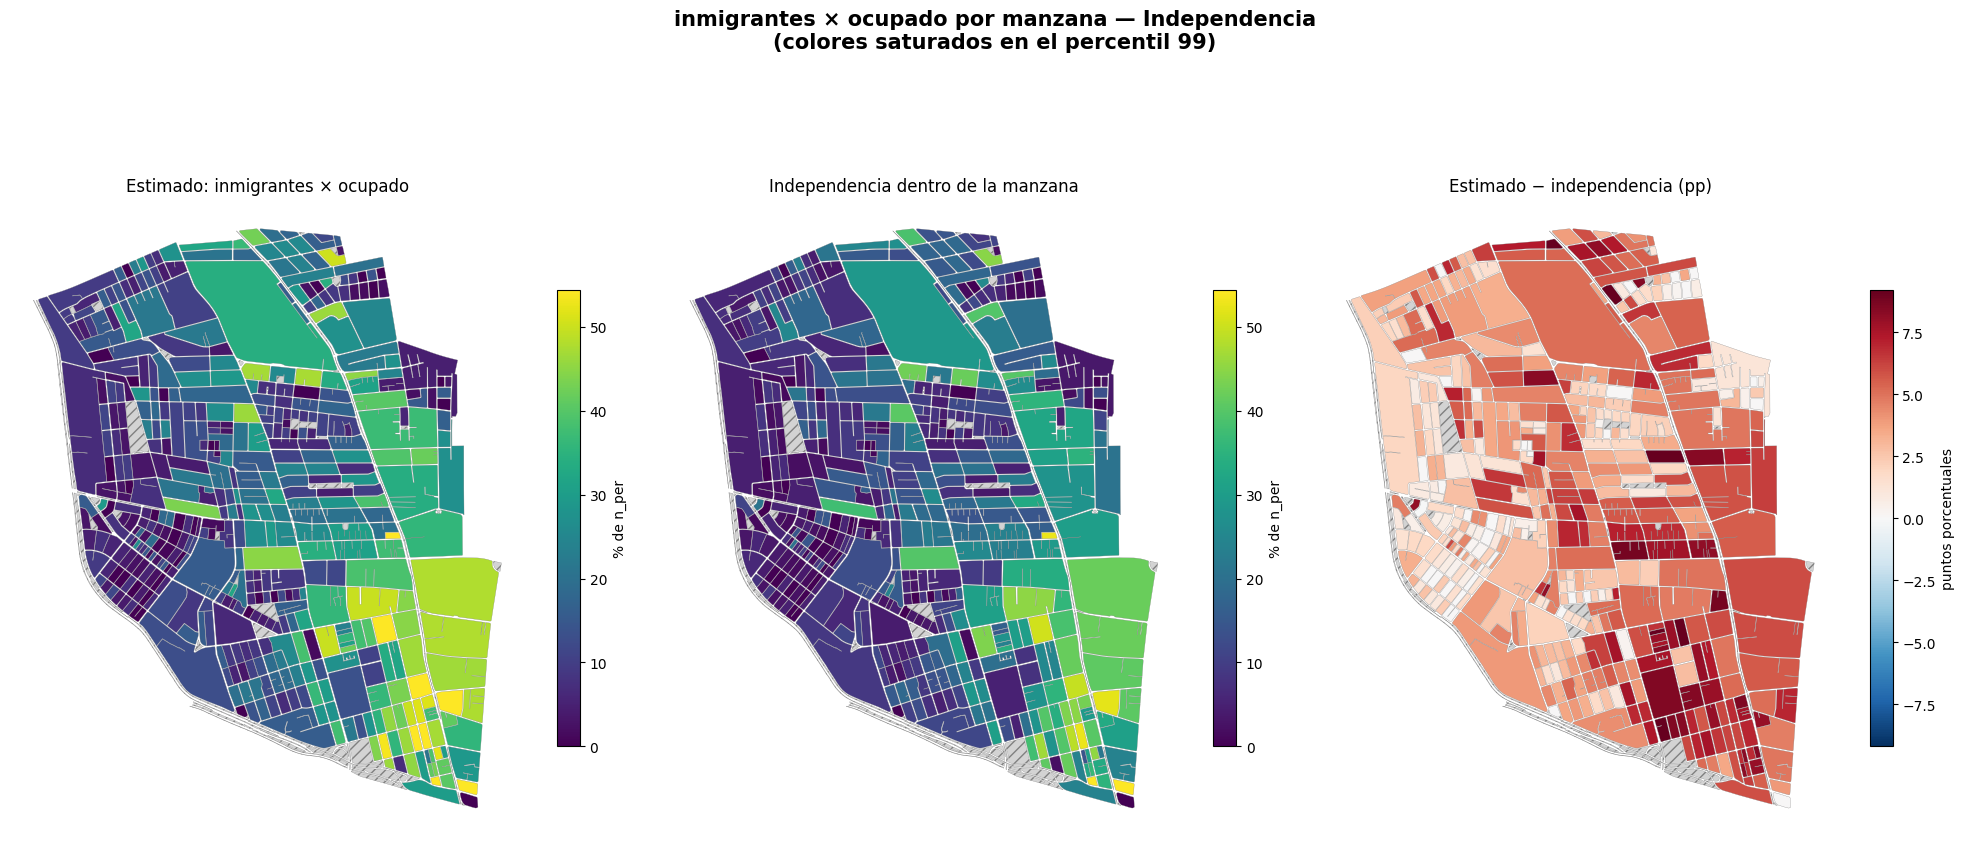

In [2]:
# Ejemplo: mapa por manzana de una celda de un cruce bivariado (estimado vs independencia dentro de la manzana)
import matplotlib.pyplot as plt
from manzanas.datos import cargar_comuna, cargar_mapa
from manzanas.inventario import construir_inventario, etiquetas_bloque
from manzanas.perfiles import codigos_bloque

CUT_MAPA = 13108
VAR1, CAT1, VAR2, CAT2 = "inmigrante", "inmigrantes", "fuerza_trabajo", "ocupado"

datos_m = cargar_comuna(CUT_MAPA, ruta_resultados=RUTA_COMUNAS)
inv_m = construir_inventario(datos_m)
ids, n_per = datos_m.manzanas_ids, datos_m.nu
cruces = pd.read_parquet(os.path.join(RUTA_PAIS, "cruces", f"cruces_{CUT_MAPA}.parquet"))
par = cruces[(cruces["var1"] == VAR1) & (cruces["var2"] == VAR2)]
assert len(par), f"no hay cruce {VAR1} × {VAR2}: {VAR1} debe ir antes que {VAR2} en el inventario"

def por_manzana(filas):
    return filas.groupby("MANZENT")["conteo"].sum().reindex(ids, fill_value=0).to_numpy()

celda = por_manzana(par[(par["cat1"] == CAT1) & (par["cat2"] == CAT2)])  # interior (inferido)
borde1 = por_manzana(par[par["cat1"] == CAT1])                            # = marginal publicado de CAT1
borde2 = por_manzana(par[par["cat2"] == CAT2])                            # = marginal publicado de CAT2
indep = borde1 * borde2 / n_per

# Chequeos: total comunal vs microdato, y bordes vs marginales publicados (NaN = manzana enmascarada)
i1, i2 = etiquetas_bloque(inv_m, VAR1).index(CAT1), etiquetas_bloque(inv_m, VAR2).index(CAT2)
cod1, nu1 = codigos_bloque(inv_m, VAR1)
cod2, nu2 = codigos_bloque(inv_m, VAR2)
total_micro = int(((cod1 == i1) & (cod2 == i2)).sum())
print(f"{CAT1} × {CAT2} en {datos_m.manzanas['COMUNA'].iloc[0]}: estimado {celda.sum():,.1f} | microdato {total_micro:,}")
print(f"max |borde - publicado|: {CAT1}={np.nanmax(np.abs(borde1 - nu1[i1])):.3f} ({np.isnan(nu1[i1]).sum()} manzanas enmascaradas) "
      f"| {CAT2}={np.nanmax(np.abs(borde2 - nu2[i2])):.3f}")

pct = lambda x: 100 * x / n_per
dif = pct(celda) - pct(indep)
print(f"% de la manzana: estimado mediana={np.median(pct(celda)):.1f}% | independencia mediana={np.median(pct(indep)):.1f}% "
      f"| diferencia media={dif.mean():+.2f} pp, |diferencia| p95={np.percentile(np.abs(dif), 95):.2f} pp")
print(f"tasa de ocupación en la comuna (microdato): {CAT1}={100 * total_micro / (cod1 == i1).sum():.1f}% "
      f"| resto={100 * ((cod1 != i1) & (cod2 == i2)).sum() / (cod1 != i1).sum():.1f}%")
assert abs(celda.sum() - total_micro) < 1

df_m = pd.DataFrame({"MANZENT": ids, "estimado": pct(celda), "independencia": pct(indep), "diferencia": dif})
mapa = cargar_mapa(CUT_MAPA).merge(df_m, on="MANZENT", how="left")
sin_dato = {"color": "lightgrey", "edgecolor": "0.5", "hatch": "///", "label": "Sin población"}
vmax = np.nanpercentile(df_m[["estimado", "independencia"]].to_numpy(), 99)
vdif = np.nanpercentile(np.abs(dif), 99)

fig, axes = plt.subplots(1, 3, figsize=(20, 10))
for ax, col, titulo, kw in [
    (axes[0], "estimado", f"Estimado: {CAT1} × {CAT2}", dict(cmap="viridis", vmin=0, vmax=vmax)),
    (axes[1], "independencia", "Independencia dentro de la manzana", dict(cmap="viridis", vmin=0, vmax=vmax)),
    (axes[2], "diferencia", "Estimado − independencia (pp)", dict(cmap="RdBu_r", vmin=-vdif, vmax=vdif)),
]:
    mapa.plot(column=col, linewidth=0.2, edgecolor="0.5", ax=ax, legend=True, missing_kwds=sin_dato,
              legend_kwds={"label": "% de n_per" if col != "diferencia" else "puntos porcentuales", "shrink": 0.5}, **kw)
    ax.set_title(titulo, fontsize=12)
    ax.axis("off")
plt.suptitle(f"{CAT1} × {CAT2} por manzana — {datos_m.manzanas['COMUNA'].iloc[0].title()}\n(colores saturados en el percentil 99)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()